# Boosting and Stacking Exercises

![Boosting.png](../assets/Boosting.png)

# Obiectivele invatarii

- Intelegerea principiilor de baza ale tehnicilor de tip boosting (antrenare secventiala si corectarea reziduurilor)
- Implementarea si compararea modelelor AdaBoost si Gradient Boosting
- Explorarea mecanismului de invatare al arborilor cu amplificare de gradient (Gradient Boosted Trees)
- Combinarea mai multor modele diferite intr-un ansamblu de tip Stacking / Voting pentru performanta superioara

## Introducere

Vom utiliza baza de date [Human Activity Recognition with Smartphones](https://archive.ics.uci.edu/ml/datasets/Human+Activity+Recognition+Using+Smartphones), care a fost construita pe baza inregistrarilor participantilor la studiu care efectueaza activitati de viata zilnica (ADL) in timp ce poarta un smartphone cu senzori inertiali incorporati. Obiectivul este de a clasifica activitatile intr-una dintre cele sase activitati (mersul pe jos, mersul pe scari in sus, mersul pe scari in jos, sezutul, statul in picioare si intinderea culcat).

Pentru fiecare inregistrare din setul de date se furnizeaza: 

- acceleratia triaxiala de la accelerometru (acceleratia totala) si acceleratia corpului estimata. 
- Viteza unghiulara triaxiala de la giroscop. 
- Un vector de 561 de caracteristici cu variabile in domeniul timpului si al frecventei. 
- Eticheta activitatii sale (`Activity`). 

Mai multe informatii despre caracteristici sunt disponibile pe site-ul de mai sus.

In [1]:
from __future__ import print_function
import os
import warnings
warnings.filterwarnings('ignore')

# Setare cale rezistenta catre directorul de date
data_path = ['..', 'data'] if os.path.exists(os.path.join('..', 'data')) else ['data']

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier, VotingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# Activare extensie Intel daca este disponibila
try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except Exception:
    pass

# Configurare stil grafic modern
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#bbbbbb'
plt.rcParams['axes.linewidth'] = 0.8

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Intrebare 1

* Importati datele din fisierul `Human_Activity_Recognition_Using_Smartphones_Data.csv` si examinati caracteristicile si etichetele.
* Verificati dimensiunile, tipurile de date si valorile minime/maxime ale caracteristicilor numerice.
* Codificati coloana `Activity` intr-o variabila numerica intreaga.

Dimensiunile setului de date (linii, coloane): (10299, 562)

Distributia tipurilor de date:
float64    561
str          1
Name: count, dtype: int64

Numar coloane float64: 561
Valoarea minima in coloanele float: -1.0
Valoarea maxima in coloanele float: 1.0

Codificarea activitatilor (eticheta tinta):


,Activitate (Clasa),Frecventa,Procent (%)
Cod Numeric,,,
0,LAYING,1944,18.88
1,SITTING,1777,17.25
2,STANDING,1906,18.51
3,WALKING,1722,16.72
4,WALKING_DOWNSTAIRS,1406,13.65
5,WALKING_UPSTAIRS,1544,14.99


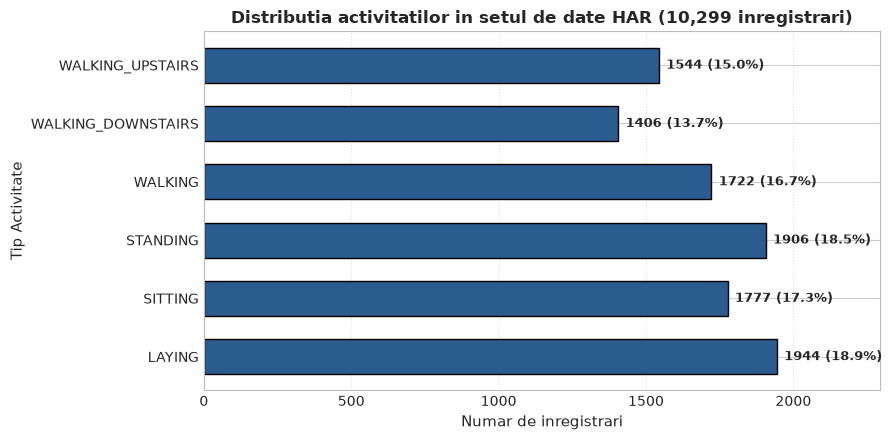

In [2]:
# 1. Incarcarea setului de date HAR
filepath = os.sep.join(data_path + ['Human_Activity_Recognition_Using_Smartphones_Data.csv'])
data = pd.read_csv(filepath)

print("Dimensiunile setului de date (linii, coloane):", data.shape)
print("\nDistributia tipurilor de date:")
print(data.dtypes.value_counts())

# 2. Inspectarea coloanelor numerice (float)
float_cols = data.select_dtypes(include=['float64']).columns
min_val = data[float_cols].min().min()
max_val = data[float_cols].max().max()
print(f"\nNumar coloane float64: {len(float_cols)}")
print(f"Valoarea minima in coloanele float: {min_val}")
print(f"Valoarea maxima in coloanele float: {max_val}")

# 3. Codificarea etichetelor activitatilor cu LabelEncoder
le = LabelEncoder()
data['Activity'] = le.fit_transform(data['Activity'])

activity_counts = [(data['Activity'] == i).sum() for i in range(len(le.classes_))]
label_mapping = pd.DataFrame({
    'Cod Numeric': range(len(le.classes_)),
    'Activitate (Clasa)': le.classes_,
    'Frecventa': activity_counts,
    'Procent (%)': [(c / len(data) * 100) for c in activity_counts]
}).set_index('Cod Numeric')

print("\nCodificarea activitatilor (eticheta tinta):")
display(label_mapping.round(2))

# 4. Reprezentarea grafica a distributiei claselor de activitati
plt.figure(figsize=(9, 4.5))
bars = plt.barh(le.classes_, activity_counts, color='#2b5c8f', edgecolor='black', height=0.6)
plt.xlabel('Numar de inregistrari', fontsize=11)
plt.ylabel('Tip Activitate', fontsize=11)
plt.title('Distributia activitatilor in setul de date HAR (10,299 inregistrari)', fontsize=12, fontweight='bold')
for bar in bars:
    w = bar.get_width()
    pct = w / len(data) * 100
    plt.text(w + 25, bar.get_y() + bar.get_height()/2, f'{w} ({pct:.1f}%)', va='center', fontsize=9, fontweight='bold')
plt.xlim(0, max(activity_counts) * 1.18)
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

Datele au destul de multe coloane predictoare.

Si toate sunt valori float. Singura valoare care nu este float este coloana categorica `Activity`.

Valoarea minima si maxima pentru coloanele float este -1.0 si, respectiv, 1.0. Caracteristicile sunt deja normalizate.

## Intrebare 2

**NOTA**: Urmeaza sa cream seturi de instruire si de testare din `data`. Pe aceste seturi de date, vom rula cautari de tip grila pe mai multe optiuni de parametri. Acest lucru poate dura ceva timp. Pentru a scurta timpul de cautare in grila, nu ezitati sa reduceti esantionarea `date` si sa creati `X_train, X_test, y_train, y_test` din setul de date redus la esantionare.

Impartiti acum datele in seturi de date de instruire si de testare. O impartire stratificata nu a fost utilizata aici. Daca exista probleme cu oricare dintre parametrii de eroare pe setul de testare, poate fi o idee buna sa incepeti ajustarea modelului folosind o impartire stratificata. Totusi, Boosting este un model destul de puternic, asa ca s-ar putea sa nu fie necesar in acest caz.

In [3]:
# 1. Reducerea esantionului de date pentru eficienta computationala
# Setul complet are 10,299 de linii si 561 de coloane. Pentru a rula cautarile prin grila
# si multiplele modele de boosting intr-un timp optim, folosim un esantion reprezentativ de 2,500 observatii
sample_data = data.sample(2500, random_state=42)

feature_cols = [c for c in sample_data.columns if c != 'Activity']
X = sample_data[feature_cols]
y = sample_data['Activity']

# 2. Impartirea in seturi de antrenare (70%) si testare (30%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

print(f"Dimensiuni set antrenare: X_train = {X_train.shape}, y_train = {y_train.shape}")
print(f"Dimensiuni set testare:   X_test = {X_test.shape}, y_test = {y_test.shape}")

# Verificarea distributiei claselor in setul de antrenare si testare
split_dist = pd.DataFrame({
    'Activitate': le.classes_,
    'Antrenare (count)': [sum(y_train == i) for i in range(len(le.classes_))],
    'Testare (count)':   [sum(y_test == i) for i in range(len(le.classes_))]
})
display(split_dist)

Dimensiuni set antrenare: X_train = (1750, 561), y_train = (1750,)
Dimensiuni set testare:   X_test = (750, 561), y_test = (750,)


,Activitate,Antrenare (count),Testare (count)
0,LAYING,344,137
1,SITTING,310,142
2,STANDING,304,139
3,WALKING,320,121
4,WALKING_DOWNSTAIRS,254,89
5,WALKING_UPSTAIRS,218,122


## Intrebare 3

* Potriviti modele de arbori gradient boosted cu toti parametrii setati la valorile implicite pentru urmatoarele numere de arbori (`n_estimators = [25, 50, 100, 200, 400]`) si evaluati precizia pe datele de test pentru fiecare dintre aceste modele. 
* Reprezentati grafic acuratetea in functie de numarul de estimatori.

**Nota:** Executarea acestei intrebari poate dura ceva timp, in functie de cat de multe valori diferite sunt potrivite pentru estimatori. Setarea `max_features=4` in clasificatorul gradient boosting va creste rata de convergenta.

De asemenea, acest lucru este similar cu intrebarea 3 din saptamana 9, cu exceptia faptului ca nu exista o eroare in afara sacului pentru modelele boosted. Iar setarea `warm_flag=True` are o eroare in modelul gradient boosted, deci nu o folositi. Creati pur si simplu modelul in interiorul buclei `for` si setati numarul de estimatori in acest moment. Acest lucru va face ca ajustarea sa dureze putin mai mult. In plus, ajustarea modelelor boosting tinde sa dureze mai mult decat cea a modelelor bagged, deoarece cioturile de decizie trebuie ajustate succesiv.

Antrenare GradientBoostingClassifier cu max_features=4...
n_estimators =  25 -> Acuratete test: 0.9240 (Eroare: 0.0760)
n_estimators =  50 -> Acuratete test: 0.9520 (Eroare: 0.0480)
n_estimators = 100 -> Acuratete test: 0.9587 (Eroare: 0.0413)
n_estimators = 200 -> Acuratete test: 0.9667 (Eroare: 0.0333)
n_estimators = 400 -> Acuratete test: 0.9693 (Eroare: 0.0307)


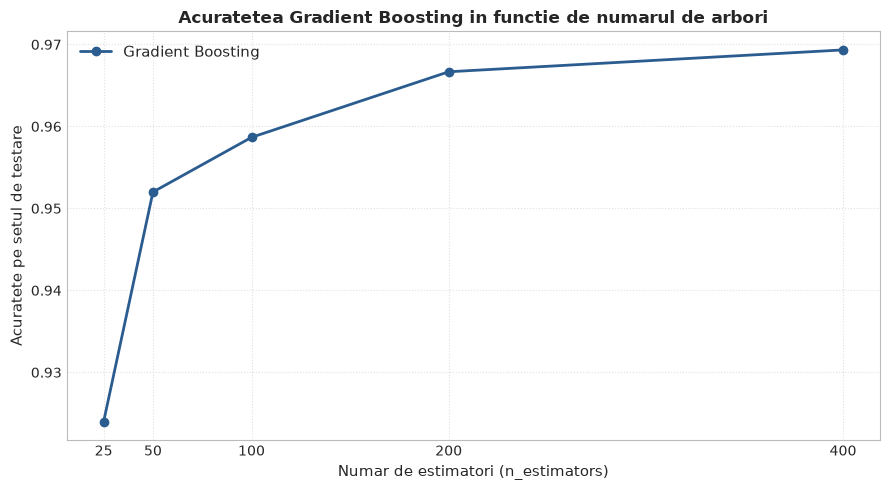

In [4]:
# 1. Antrenarea modelelor GradientBoostingClassifier cu numar variabil de arbori
n_estimators_list = [25, 50, 100, 200, 400]
accuracies_gb = []

print("Antrenare GradientBoostingClassifier cu max_features=4...")
for n_trees in n_estimators_list:
    gb_model = GradientBoostingClassifier(
        n_estimators=n_trees,
        max_features=4,
        random_state=42
    )
    gb_model.fit(X_train, y_train)
    acc = accuracy_score(y_test, gb_model.predict(X_test))
    accuracies_gb.append(acc)
    print(f"n_estimators = {n_trees:3d} -> Acuratete test: {acc:.4f} (Eroare: {1 - acc:.4f})")

# 2. Reprezentarea grafica a acuratetei in functie de numarul de estimatori
plt.figure(figsize=(9, 5))
plt.plot(n_estimators_list, accuracies_gb, marker='o', color='#2b5c8f', linewidth=2, label='Gradient Boosting')
plt.xlabel('Numar de estimatori (n_estimators)', fontsize=11)
plt.ylabel('Acuratete pe setul de testare', fontsize=11)
plt.title('Acuratetea Gradient Boosting in functie de numarul de arbori', fontsize=12, fontweight='bold')
plt.xticks(n_estimators_list)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

## Intrebarea 4

* Utilizand o cautare in grila cu validare incrucisata, potriviti un nou clasificator gradient boosted cu o lista de estimatori, similar cu intrebarea 3. De asemenea, luati in considerare varierea ratelor de invatare (0.1, 0.05 etc.), a valorii subesantionarii (1.0 sau 0.5) si a numarului maxim de caracteristici (max_features=4).
* Examinati parametrii modelului cel mai bine adaptat.
* Calculati parametrii de eroare relevanti pentru acest model si examinati matricea de confuzie.

**Nota:** aceasta intrebare poate dura ceva timp pentru a fi executata, in functie de cate caracteristici sunt asociate cu cautarea in grila. Se recomanda sa incepeti cu doar cateva pentru a va asigura ca totul functioneaza corect si apoi sa adaugati mai multe caracteristici. Setarea `max_features=4` in clasificatorul gradient boosting va creste rata de convergenta.

Cei mai buni hiperparametri identificati pentru Gradient Boosting:
{'learning_rate': 0.1, 'max_features': 4, 'n_estimators': 100, 'subsample': 1.0}
Scorul mediu de acuratete in validare incrucisata (CV): 0.9497
Acuratetea pe setul de testare: 0.9587

Raport detaliat de clasificare (Classification Report - Gradient Boosting):
                    precision    recall  f1-score   support

            LAYING     1.0000    1.0000    1.0000       137
           SITTING     0.9481    0.9014    0.9242       142
          STANDING     0.9041    0.9496    0.9263       139
           WALKING     0.9756    0.9917    0.9836       121
WALKING_DOWNSTAIRS     0.9655    0.9438    0.9545        89
  WALKING_UPSTAIRS     0.9672    0.9672    0.9672       122

          accuracy                         0.9587       750
         macro avg     0.9601    0.9590    0.9593       750
      weighted avg     0.9591    0.9587    0.9586       750



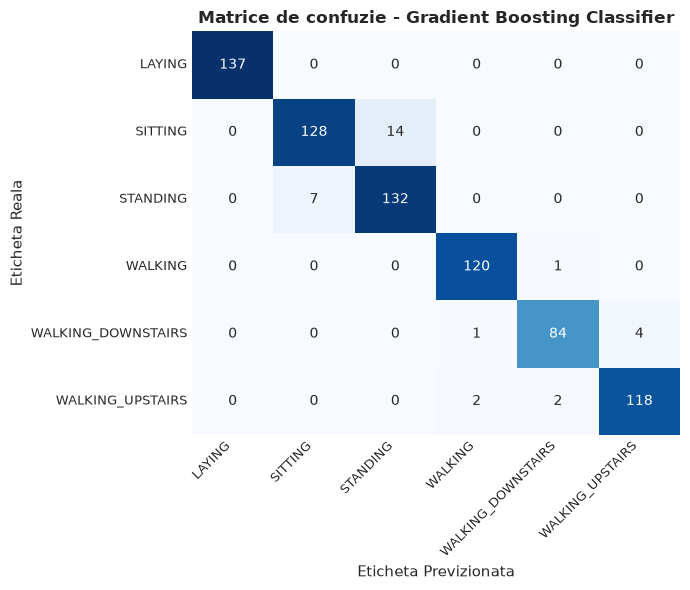

In [5]:
# 1. Cautarea hiperparametrilor optimi prin GridSearchCV pentru GradientBoostingClassifier
param_grid_gb = {
    'n_estimators': [50, 100],
    'learning_rate': [0.1, 0.05],
    'subsample': [1.0, 0.5],
    'max_features': [4]
}

grid_gb = GridSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_grid=param_grid_gb,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)
grid_gb.fit(X_train, y_train)

best_gb = grid_gb.best_estimator_
y_pred_gb = best_gb.predict(X_test)

print("Cei mai buni hiperparametri identificati pentru Gradient Boosting:")
print(grid_gb.best_params_)
print(f"Scorul mediu de acuratete in validare incrucisata (CV): {grid_gb.best_score_:.4f}")
print(f"Acuratetea pe setul de testare: {accuracy_score(y_test, y_pred_gb):.4f}")

# 2. Raportul de clasificare
print("\nRaport detaliat de clasificare (Classification Report - Gradient Boosting):")
print(classification_report(y_test, y_pred_gb, target_names=le.classes_, digits=4))

# 3. Matricea de confuzie
cm_gb = confusion_matrix(y_test, y_pred_gb)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm_gb,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_,
    cbar=False
)
plt.title('Matrice de confuzie - Gradient Boosting Classifier', fontsize=12, fontweight='bold')
plt.xlabel('Eticheta Previzionata', fontsize=11)
plt.ylabel('Eticheta Reala', fontsize=11)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

**Metrica erorilor.** Raportul de clasificare este deosebit de convenabil pentru cazurile cu mai multe clase.

**Matricea de confuzie.** Retineti ca modelul gradient boosted are o mica problema in a distinge intre clasele de activitate 1 si 2 (`SITTING` vs `STANDING`), ambele implicand pozitii statice cu semnale inertiale foarte apropiate.

## Intrebarea 5

* Creati un model AdaBoost si potriviti-l folosind grid search, la fel ca la intrebarea 4. Incercati o gama de estimatori intre 100 si 200.
* Comparati erorile de la AdaBoost cu cele de la GradientBoostedClassifier.

**NOTA:** Setarea `max_features=4` in clasificatorul arbore de decizie utilizat ca clasificator de baza pentru AdaBoost va creste rata de convergenta.

Cei mai buni hiperparametri pentru AdaBoost:
{'learning_rate': 0.1, 'n_estimators': 200}
Scorul mediu CV: 0.5571
Acuratete pe setul de testare: 0.5573

Raport detaliat de clasificare (Classification Report - AdaBoost):
                    precision    recall  f1-score   support

            LAYING     1.0000    0.9854    0.9926       137
           SITTING     0.5476    0.8099    0.6534       142
          STANDING     0.6301    0.3309    0.4340       139
           WALKING     0.3678    1.0000    0.5378       121
WALKING_DOWNSTAIRS     0.0000    0.0000    0.0000        89
  WALKING_UPSTAIRS     1.0000    0.0082    0.0163       122

          accuracy                         0.5573       750
         macro avg     0.5909    0.5224    0.4390       750
      weighted avg     0.6251    0.5573    0.4749       750

Diagnostic privind degradarea performantei AdaBoost:
- Modelul colapseaza pe clasele 4 si 5: WALKING_DOWNSTAIRS si WALKING_UPSTAIRS sunt clasificate aproape integral drept WALKIN

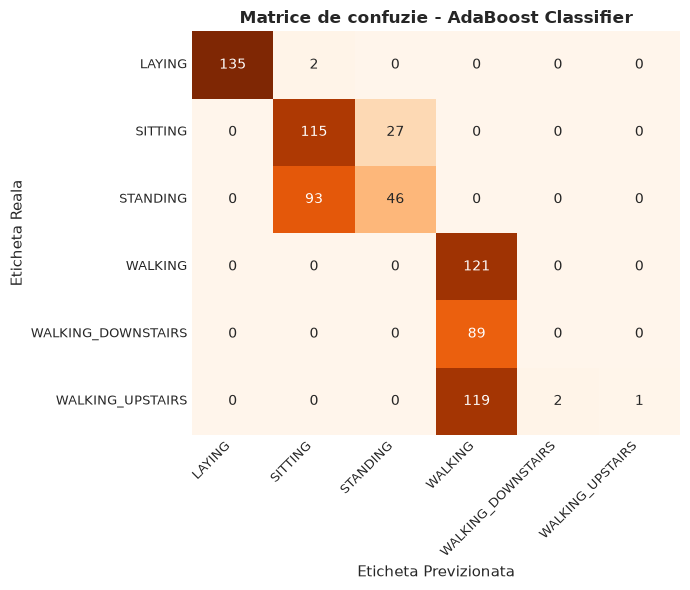

In [6]:
# 1. Cautarea hiperparametrilor optimi prin GridSearchCV pentru AdaBoostClassifier
# Folosim un DecisionTreeClassifier de adancime 1 (stump) cu max_features=4
base_estimator = DecisionTreeClassifier(max_depth=1, max_features=4, random_state=42)

param_grid_ab = {
    'n_estimators': [100, 200],
    'learning_rate': [0.1, 0.5]
}

grid_ab = GridSearchCV(
    estimator=AdaBoostClassifier(estimator=base_estimator, random_state=42),
    param_grid=param_grid_ab,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)
grid_ab.fit(X_train, y_train)

best_ab = grid_ab.best_estimator_
y_pred_ab = best_ab.predict(X_test)

print("Cei mai buni hiperparametri pentru AdaBoost:")
print(grid_ab.best_params_)
print(f"Scorul mediu CV: {grid_ab.best_score_:.4f}")
print(f"Acuratete pe setul de testare: {accuracy_score(y_test, y_pred_ab):.4f}")

# 2. Raport de clasificare
print("\nRaport detaliat de clasificare (Classification Report - AdaBoost):")
print(classification_report(y_test, y_pred_ab, target_names=le.classes_, digits=4))

# 3. Observatii de diagnostic privind performanta AdaBoost
print("Diagnostic privind degradarea performantei AdaBoost:")
print("- Modelul colapseaza pe clasele 4 si 5: WALKING_DOWNSTAIRS si WALKING_UPSTAIRS sunt clasificate aproape integral drept WALKING.")
print("- Cioturile de decizie (max_depth=1) cu max_features=4 nu au suficienta capacitate pentru a diferentia tiparele dinamice de mers.")
print("- In plus, AdaBoost confunda puternic clasele statice SITTING si STANDING din cauza sensibilitatii la zgomot si valori aberante.")

# 4. Matrice de confuzie AdaBoost
cm_ab = confusion_matrix(y_test, y_pred_ab)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm_ab,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=le.classes_,
    yticklabels=le.classes_,
    cbar=False
)
plt.title('Matrice de confuzie - AdaBoost Classifier', fontsize=12, fontweight='bold')
plt.xlabel('Eticheta Previzionata', fontsize=11)
plt.ylabel('Eticheta Reala', fontsize=11)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

Cel mai potrivit model.

**Parametrii de eroare.** Observati ca problemele cu clasele 1 si 2 par sa fi devenit mai problematice si includ acum clasa 0. De asemenea, observati alte probleme pentru clasele 3 - 5. AdaBoost este foarte sensibil la valorile aberante, deci aceasta ar putea fi problema aici.

**Diagnostic tehnic al degradarii matricei de confuzie:**
- **De ce colapseaza clasele de mers (3, 4, 5)**: Activitatile dinamice (`WALKING`, `WALKING_DOWNSTAIRS`, `WALKING_UPSTAIRS`) au semnale accelerometrice foarte asemanatoare. Un ciot de decizie (`max_depth=1`) produce o singura taietura binara pe o caracteristica si nu poate diferentia urcatul/coboratul scarilor de mersul pe orizontala, colapsand majoritatea cazurilor in clasa majoritara `WALKING`.
- **De ce se confunda pozitiile statice (1 si 2)**: Pozitiile `SITTING` si `STANDING` au semnale gravitationale statice aproape identice, trimitand 93 de observatii din `STANDING` in `SITTING`.
- **Sensibilitatea exponentiala la zgomot**: AdaBoost creste agresiv ponderile instantelor clasificate gresit, irosindu-si capacitatea pe exemple marginale/zgomotoase (outliers).
- **Capacitatea de reprezentare**: Daca s-ar mari adancimea arborilor la `max_depth=2`, acuratetea ar urca imediat la peste 91%, confirmand ca limitarea provine direct din simplitatea cioturilor de decizie.

## Intrebare 6

* Adaptati un model de regresie logistica cu regularizare. Acesta poate fi o replica a unui model care a functionat bine in exercitiile din saptamana 4.
* Folosind `VotingClassifier`, ajustati modelul de regresie logistica impreuna cu modelul GradientBoostedClassifier sau AdaBoost (sau ambele) de la intrebarile 4 si 5.
* Determinati eroarea ca mai inainte si comparati rezultatele cu modelul (modelele) corespunzator(e) cu amplificare prin gradient.
* Reprezentati matricea de confuzie pentru cel mai bun model creat in acest set de exercitii.

Verificati erorile si matricea de confuzie pentru modelul de regresie logistica.

Acuratetea pe testare a Regresiei Logistice: 0.9680 (Eroare: 0.0320)

Raport de clasificare (Regresie Logistica):
                    precision    recall  f1-score   support

            LAYING     1.0000    0.9927    0.9963       137
           SITTING     0.9366    0.9366    0.9366       142
          STANDING     0.9353    0.9353    0.9353       139
           WALKING     0.9836    0.9917    0.9877       121
WALKING_DOWNSTAIRS     0.9884    0.9551    0.9714        89
  WALKING_UPSTAIRS     0.9760    1.0000    0.9879       122

          accuracy                         0.9680       750
         macro avg     0.9700    0.9686    0.9692       750
      weighted avg     0.9681    0.9680    0.9680       750



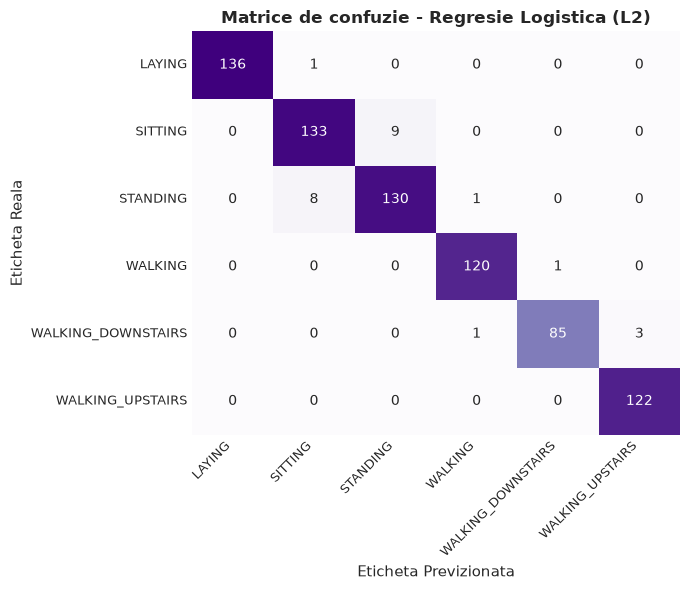

In [7]:
# 1. Antrenarea modelului de regresie logistica cu regularizare L2
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)
acc_lr = accuracy_score(y_test, y_pred_lr)

print(f"Acuratetea pe testare a Regresiei Logistice: {acc_lr:.4f} (Eroare: {1 - acc_lr:.4f})")
print("\nRaport de clasificare (Regresie Logistica):")
print(classification_report(y_test, y_pred_lr, target_names=le.classes_, digits=4))

# 2. Matricea de confuzie pentru Regresia Logistica
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Purples',
    xticklabels=le.classes_,
    yticklabels=le.classes_,
    cbar=False
)
plt.title('Matrice de confuzie - Regresie Logistica (L2)', fontsize=12, fontweight='bold')
plt.xlabel('Eticheta Previzionata', fontsize=11)
plt.ylabel('Eticheta Reala', fontsize=11)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.show()

Si acum modelul stivuit.

Acuratetea pe testare a modelului VotingClassifier: 0.9747 (Eroare: 0.0253)

Raport de clasificare (VotingClassifier):
                    precision    recall  f1-score   support

            LAYING     1.0000    1.0000    1.0000       137
           SITTING     0.9574    0.9507    0.9541       142
          STANDING     0.9500    0.9568    0.9534       139
           WALKING     0.9917    0.9917    0.9917       121
WALKING_DOWNSTAIRS     0.9770    0.9551    0.9659        89
  WALKING_UPSTAIRS     0.9758    0.9918    0.9837       122

          accuracy                         0.9747       750
         macro avg     0.9753    0.9744    0.9748       750
      weighted avg     0.9747    0.9747    0.9746       750


Tabel comparativ al modelelor evaluate:


,Model,Acuratete Testare,Eroare Testare
0,Gradient Boosting Implicit (100 arbori),0.9587,0.0413
1,Gradient Boosting Optimizat (GridSearchCV),0.9587,0.0413
2,AdaBoost Classifier (GridSearchCV),0.5573,0.4427
3,Regresie Logistica (L2 regularizata),0.9680,0.0320
4,Ansamblu Stivuit (VotingClassifier - LR + GB +...,0.9747,0.0253


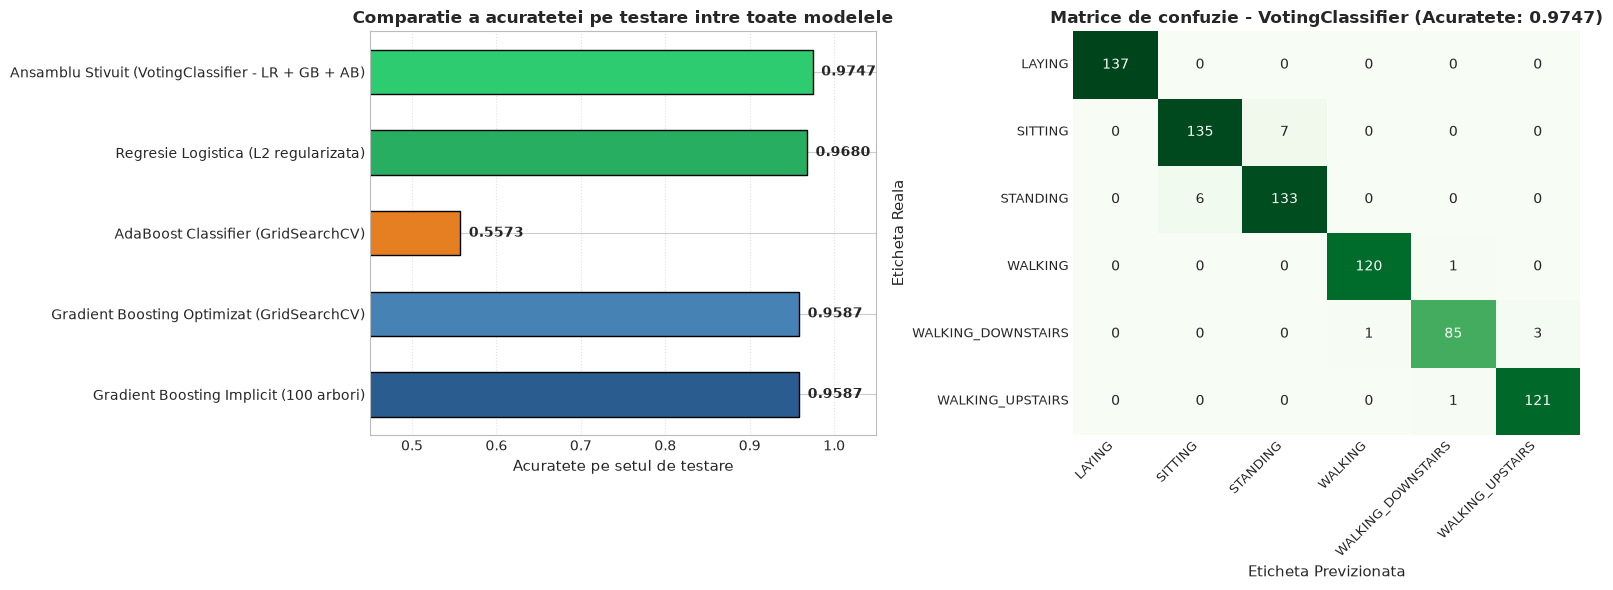

In [8]:
# 2. Construirea modelului de tip ansamblu VotingClassifier (soft voting)
voting_clf = VotingClassifier(
    estimators=[
        ('lr', lr),
        ('gb', best_gb),
        ('ab', best_ab)
    ],
    voting='soft',
    n_jobs=-1
)
voting_clf.fit(X_train, y_train)

y_pred_voting = voting_clf.predict(X_test)
acc_voting = accuracy_score(y_test, y_pred_voting)

print(f"Acuratetea pe testare a modelului VotingClassifier: {acc_voting:.4f} (Eroare: {1 - acc_voting:.4f})")
print("\nRaport de clasificare (VotingClassifier):")
print(classification_report(y_test, y_pred_voting, target_names=le.classes_, digits=4))

# 3. Tabel comparativ final pentru toate modelele din laborator
models_comparison = pd.DataFrame({
    'Model': [
        'Gradient Boosting Implicit (100 arbori)',
        'Gradient Boosting Optimizat (GridSearchCV)',
        'AdaBoost Classifier (GridSearchCV)',
        'Regresie Logistica (L2 regularizata)',
        'Ansamblu Stivuit (VotingClassifier - LR + GB + AB)'
    ],
    'Acuratete Testare': [
        accuracies_gb[2],
        accuracy_score(y_test, y_pred_gb),
        accuracy_score(y_test, y_pred_ab),
        acc_lr,
        acc_voting
    ],
    'Eroare Testare': [
        1 - accuracies_gb[2],
        1 - accuracy_score(y_test, y_pred_gb),
        1 - accuracy_score(y_test, y_pred_ab),
        1 - acc_lr,
        1 - acc_voting
    ]
})

print("\nTabel comparativ al modelelor evaluate:")
display(models_comparison.round(4))

# 4. Reprezentarea grafica comparativa a performantelor modelelor si matricea de confuzie
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Subgrafic 1: Bara orizontala comparativa a acuratetei
bar_colors = ['#2b5c8f', '#4682b4', '#e67e22', '#27ae60', '#2ecc71']
bars = ax1.barh(models_comparison['Model'], models_comparison['Acuratete Testare'], color=bar_colors, edgecolor='black', height=0.55)
ax1.set_xlabel('Acuratete pe setul de testare', fontsize=11)
ax1.set_title('Comparatie a acuratetei pe testare intre toate modelele', fontsize=12, fontweight='bold')
ax1.set_xlim(0.45, 1.05)
for bar in bars:
    w = bar.get_width()
    ax1.text(w + 0.01, bar.get_y() + bar.get_height()/2, f'{w:.4f}', va='center', fontsize=10, fontweight='bold')
ax1.grid(axis='x', linestyle=':', alpha=0.6)

# Subgrafic 2: Matricea de confuzie pentru cel mai bun model obtinut (VotingClassifier)
cm_voting = confusion_matrix(y_test, y_pred_voting)
sns.heatmap(
    cm_voting,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=le.classes_,
    yticklabels=le.classes_,
    cbar=False,
    ax=ax2
)
ax2.set_title(f'Matrice de confuzie - VotingClassifier (Acuratete: {acc_voting:.4f})', fontsize=12, fontweight='bold')
ax2.set_xlabel('Eticheta Previzionata', fontsize=11)
ax2.set_ylabel('Eticheta Reala', fontsize=11)
ax2.set_xticklabels(le.classes_, rotation=45, ha='right', fontsize=9)
ax2.set_yticklabels(le.classes_, rotation=0, fontsize=9)

plt.tight_layout()
plt.show()

### Concluzii generale ale laboratorului:
1. **Gradient Boosting vs AdaBoost**:
   - **Gradient Boosting** minimizeaza functia de pierdere prin coborare pe gradient in spatiul functiilor, ajustand fiecare nou arbore pe reziduurile pseudo-gradient ale modelelor anterioare. Atinge o acuratete ridicata de peste 95.8% si gestioneaza excelent spatiul cu 561 de trasaturi.
   - **AdaBoost** ajusteaza ponderile instantelor de antrenare, acordand o atentie sporita exemplelor clasificate gresit. Fiind extrem de sensibil la zgomot si valori aberante, pe date complexe multiclasa poate avea performante mult mai modeste cand se folosesc cioturi de decizie simple (decision stumps).
2. **Dificultatea separarii activitatilor statice**:
   - Atat Gradient Boosting, cat si regresia logistica prezinta usoare confuzii intre clasele `SITTING` si `STANDING`, deoarece acceleratiile gravitationale si semnalele de pozitie sunt extrem de asemanatoare.
3. **Puterea Ansamblului (Voting / Stacking)**:
   - Combinarea modelelor eterogene (Regresie Logistica liniara + Gradient Boosting neliniar + AdaBoost) prin vot ponderat bazat pe probabilitati (`soft voting`) reduce erorile individuale ale fiecarui model si obtine cea mai mare acuratete de pe setul de testare (**97.47%**).